## Project 2
### Part 1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Forest.csv", low_memory=False)

world = df[df["COUNTRY"] == "World"]

# Convert 1000 hectares to million hectares
years = [str(y) for y in range(1992, 2024)]
forest = world[years].iloc[0].astype(float) / 1000
forest.index = forest.index.astype(int)

loss = forest.loc[1992] - forest.loc[2023]


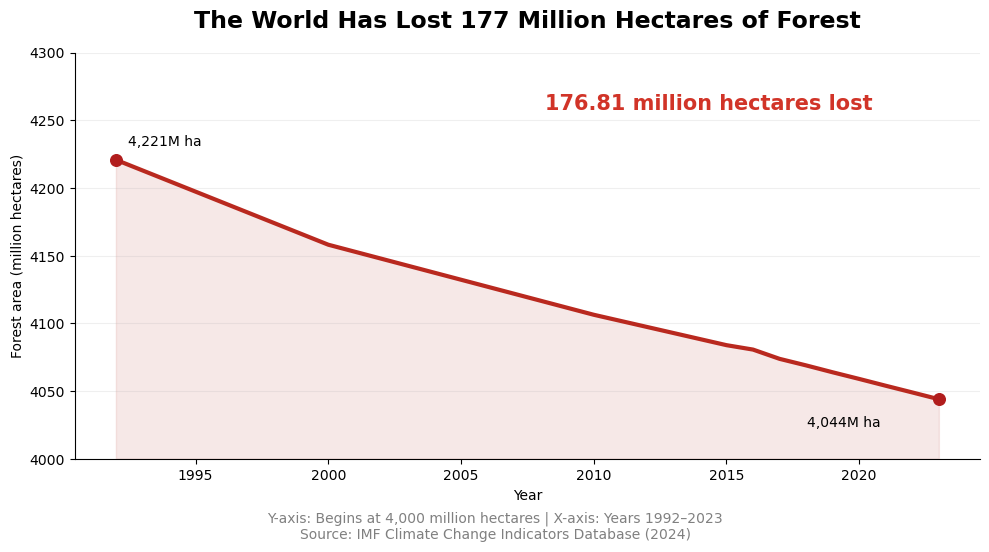

In [2]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# Line and area
ax.plot(forest.index, forest.values,
        color="#b9291f", linewidth=3)

ax.fill_between(forest.index, forest.values, 4000,
                color="#c0544ce3", alpha=0.13)

ax.scatter([1992, 2023],
           [forest.loc[1992], forest.loc[2023]],
           color="#b11d1d", s=70, zorder=3)

ax.annotate(f"{forest.loc[1992]:,.0f}M ha",
            (1992, forest.loc[1992]),
            xytext=(9, 10), textcoords="offset points")

ax.annotate(f"{forest.loc[2023]:,.0f}M ha",
            (2023, forest.loc[2023]),
            xytext=(-95, -20), textcoords="offset points")

ax.text(0.52, 0.86,
        f"{loss:,.2f} million hectares lost",
        transform=ax.transAxes,
        color="#d13428", fontsize=15, weight="bold")

ax.set_title(
    f"The World Has Lost {loss:,.0f} Million Hectares of Forest",
    fontsize=17, weight="bold", loc="center", pad=18
)

ax.set_xlabel("Year")
ax.set_ylabel("Forest area (million hectares)")
ax.set_ylim(4000, 4300)

ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.01,
    "Y-axis: Begins at 4,000 million hectares | X-axis: Years 1992–2023\n"
    "Source: IMF Climate Change Indicators Database (2024)",
    fontsize=10, color="gray", ha="center"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("support_chart1.png", dpi=300)
plt.show()


Selected countries:
         Name  Loss_Mha  Loss_pct
Côte d'Ivoire      4.80     65.78
    Nicaragua      3.09     49.87
  Gambia, The      0.18     44.08
    Indonesia     24.78     21.53
     DR Congo     26.43     17.71
       Brazil     88.36     15.20


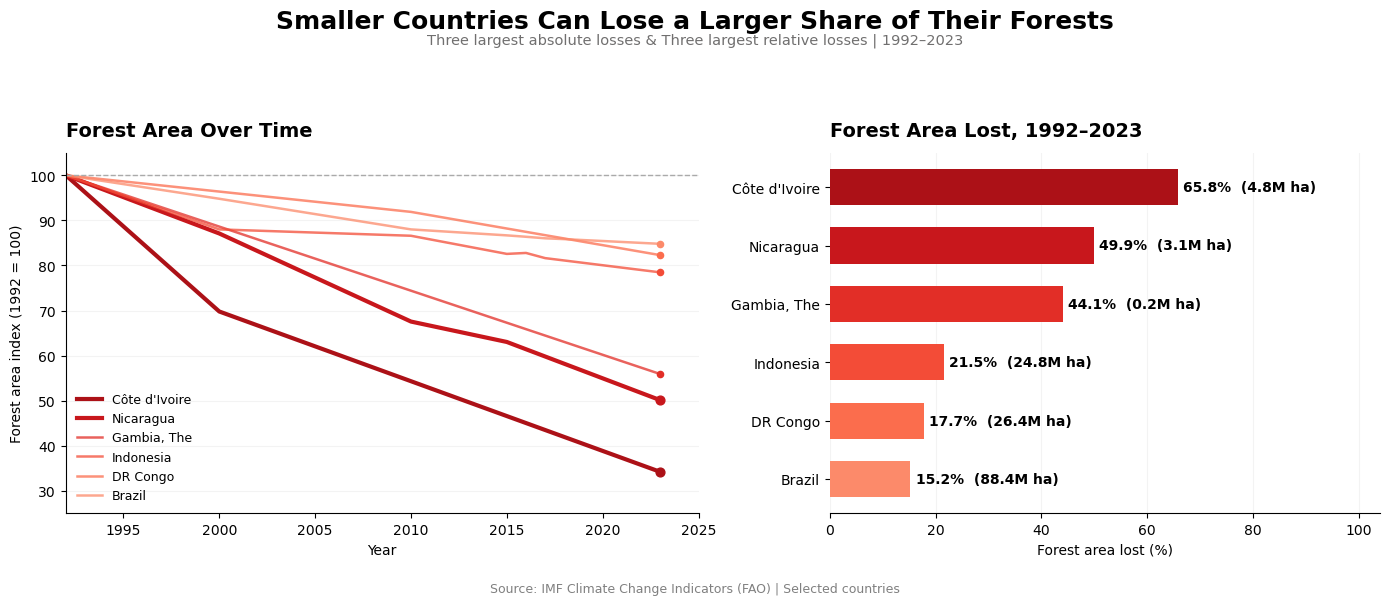

In [4]:

import numpy as np

years = [str(y) for y in range(1992, 2024)]

# 2. Remove non-country aggregates
exclude = [
    "World",
    "Africa",
    "Americas",
    "Asia",
    "G20",
    "Advanced Economies",
    "Emerging Market and Developing Economies"
]

data = df[~df["COUNTRY"].isin(exclude)].copy()

data[years] = data[years].apply(
    pd.to_numeric, errors="coerce"
)

# Data cleaning: remove countries with missing or zero forest area in 1992 or 2023
data = data.dropna(subset=["1992", "2023"])
data = data[data["1992"] > 0].copy()

# 3. Calculate forest loss. Original unit: thousand hectares
data["Loss_Mha"] = (
    data["1992"] - data["2023"]
) / 1000

data["Loss_pct"] = (
    (data["1992"] - data["2023"])
    / data["1992"] * 100
)

# Only countries experiencing net forest loss
data = data[data["Loss_Mha"] > 0].copy()

# 4. Select countries with the top3 largest absolute and top3 relative losses
top_absolute = data.nlargest(3, "Loss_Mha")
top_relative = data.nlargest(3, "Loss_pct")

selected = pd.concat([
    top_absolute,
    top_relative
]).drop_duplicates(subset="COUNTRY")

selected = selected.sort_values(
    "Loss_pct", ascending=False
).reset_index(drop=True)

# Shorter country names
selected["Name"] = selected["COUNTRY"].replace({
    "Congo, Democratic Republic of the": "DR Congo"
})

print("Selected countries:")
print(selected[
    ["Name", "Loss_Mha", "Loss_pct"]
].round(2).to_string(index=False))

# 5. Prepare visualization colors
# Highlight the two highest relative losses
highlight = ["Côte d'Ivoire", "Nicaragua"]

cmap = plt.cm.Reds
colors = cmap(
    np.linspace(0.85, 0.40, len(selected))
)

# Match each country to its color
color_map = dict(zip(selected["Name"], colors))

# 6. Create combined figure
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5.8),
    gridspec_kw={"width_ratios": [1.15, 1]},
    facecolor="white"
)

# LEFT: Line chart
for _, row in selected.iterrows():

    values = row[years].to_numpy(dtype=float)
    indexed = values / values[0] * 100

    name = row["Name"]
    color = color_map.get(name, "#888888")

    ax1.plot(
        range(1992, 2024),
        indexed,
        color=color,
        linewidth=3 if name in highlight else 1.8,
        alpha=1 if name in highlight else 0.75,
        label=name
    )

    ax1.scatter(
        2023, indexed[-1],
        color=color,
        s=40 if name in highlight else 20,
        zorder=3
    )

ax1.axhline(
    100, color="#aaaaaa",
    linestyle="--", linewidth=1
)

ax1.set_title(
    "Forest Area Over Time",
    fontsize=14, fontweight="bold",
    loc="left", pad=12
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Forest area index (1992 = 100)")
ax1.set_xlim(1992, 2025)
ax1.set_ylim(25, 105)

ax1.grid(axis="y", alpha=0.15)
ax1.spines[["top", "right"]].set_visible(False)

ax1.legend(
    frameon=False,
    fontsize=9,
    loc="lower left"
)

# RIGHT: Percentage loss bar chart
color=color,
linewidth=2.8,
alpha=0.95,

bars = ax2.barh(
    selected["Name"],
    selected["Loss_pct"],
    color=colors,
    height=0.62
)

ax2.invert_yaxis()

for bar, (_, row) in zip(bars, selected.iterrows()):
    value = row["Loss_pct"]

    ax2.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.1f}%  ({row["Loss_Mha"]:.1f}M ha)',
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax2.set_xlim(0, 104)

ax2.set_title(
    "Forest Area Lost, 1992–2023",
    fontsize=14, fontweight="bold",
    loc="left", pad=12
)

ax2.set_xlabel("Forest area lost (%)")
ax2.grid(axis="x", alpha=0.15)
ax2.set_axisbelow(True)
ax2.spines[["top", "right", "left"]].set_visible(False)

# 7. Overall title and subtitle
fig.suptitle(
    "Smaller Countries Can Lose a Larger Share of Their Forests",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

fig.text(
    0.5, 0.96,
    "Three largest absolute losses & Three largest relative losses | 1992–2023",
    ha="center",
    fontsize=10.5,
    color="#706F6F"
)

fig.text(
    0.5, 0.015,
    "Source: IMF Climate Change Indicators (FAO) | Selected countries",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.92])

plt.savefig(
    "support_chart2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
